# 02 - Model training, tuning and MLflow experiment tracking
Runs `python -m heartrisk.train` (config: `configs/train.yaml`): Logistic Regression, Random Forest and Gradient Boosting, each tuned with GridSearchCV + stratified 5-fold CV; every hyper-parameter combination is logged as an MLflow child run. Start the UI with `mlflow ui --backend-store-uri sqlite:///mlflow.db`.

In [1]:
# Make the repository's src/ importable whether or not `pip install -e .` was run
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)
import platform, socket, datetime
print("Run on host:", socket.gethostname(), "| Python", platform.python_version(),
      "| started", datetime.datetime.now().isoformat(timespec="seconds"))

Run on host: ip-10-3-24-59.ap-south-1.compute.internal | Python 3.12.9 | started 2026-10-16T20:18:53


In [2]:
import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s %(levelname)s %(name)s: %(message)s', force=True)
from heartrisk.train import run
out = run()   # same code path as `python -m heartrisk.train`
print('Selected:', out['selected_model'])

2026/10/16 20:19:11 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/16 20:19:11 INFO mlflow.store.db.utils: Updating database tables
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step
INFO  [alembic.runtime.migration] Running upgrade 451aebb31d03 -> 90e64c465722, migrate user column to tags
INFO  [alembic.runtime.migration] Running upgrade 90e64c465722 -> 181f10493468, allow nulls for metric values
INFO  [alembic.runtime.migration] Running upgrade 181f10493468 -> df50e92ffc5e, Add Experiment Tags Table
INFO  [alembic.runtime.migration] Running upgrade df50e92ffc5e -> 7ac759974ad8, Update run tags with larger limit
INFO  [alembic.runtime.migration] Running upgrade 7ac759974ad8 -> 89d4b8295536, create latest metrics table
INFO  [89d4b8295536_create_latest_metrics_table_py] Migration complete!
INFO  

Selected: logistic_regression


In [3]:
import json, pandas as pd
m = json.load(open('reports/metrics.json'))
cols = ['model','cv_roc_auc_mean','cv_roc_auc_std','cv_accuracy_mean','cv_precision_mean','cv_recall_mean','cv_f1_mean',
        'test_roc_auc','test_accuracy','test_precision','test_recall','overfit_gap_roc_auc']
pd.DataFrame(m['models'])[cols].round(4)

,model,cv_roc_auc_mean,cv_roc_auc_std,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,test_roc_auc,test_accuracy,test_precision,test_recall,overfit_gap_roc_auc
0,logistic_regression,0.9071,0.0190,0.8552,0.8608,0.8281,0.8404,0.9589,0.8852,0.8182,0.9643,0.0244
1,random_forest,0.9005,0.0249,0.8345,0.8437,0.7917,0.8128,0.9600,0.9016,0.8667,0.9286,0.0634
2,gradient_boosting,0.8755,0.0273,0.8304,0.8327,0.8012,0.8117,0.9535,0.9016,0.8667,0.9286,0.1069


In [4]:
print('Selected model:', m['selected_model'])
print('Reason:', m['selection_reason'])
for r in m['models']:
    print(r['model'], 'best params ->', r['best_params'])

Selected model: logistic_regression
Reason: logistic_regression has the highest mean CV roc_auc (0.9071).
logistic_regression best params -> {'clf__C': 1.0, 'clf__class_weight': 'balanced', 'clf__penalty': 'l2', 'features__add_hr_ratio': False}
random_forest best params -> {'clf__max_depth': 5, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5, 'features__add_hr_ratio': False}
gradient_boosting best params -> {'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__n_estimators': 100, 'features__add_hr_ratio': True}


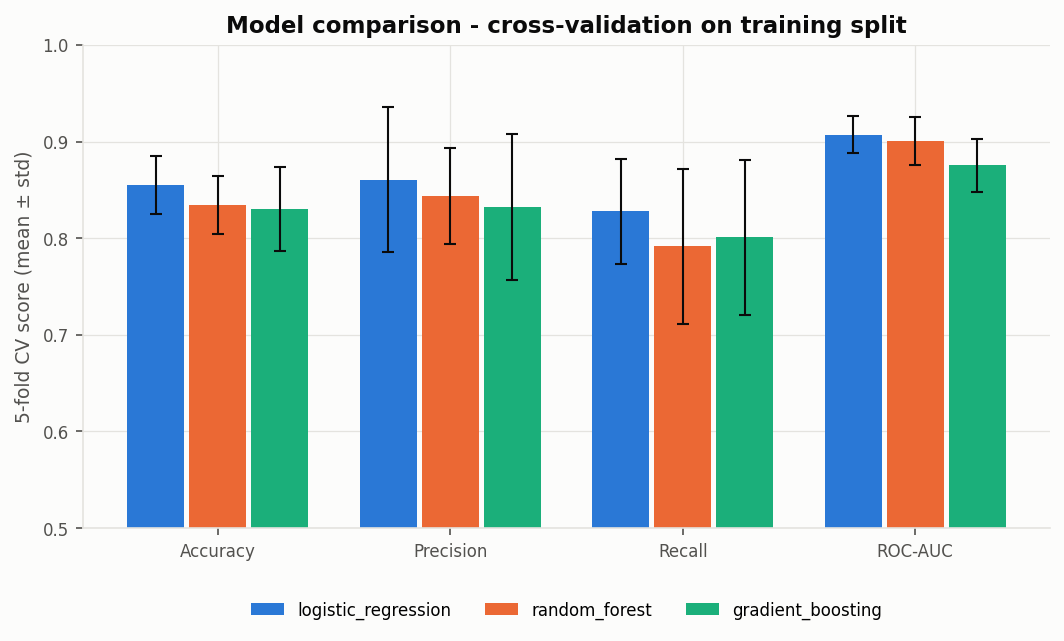

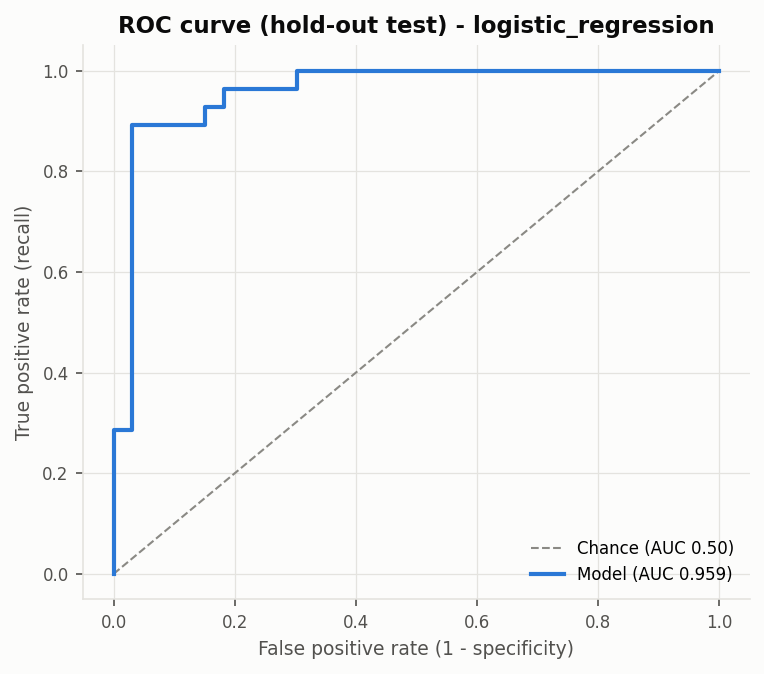

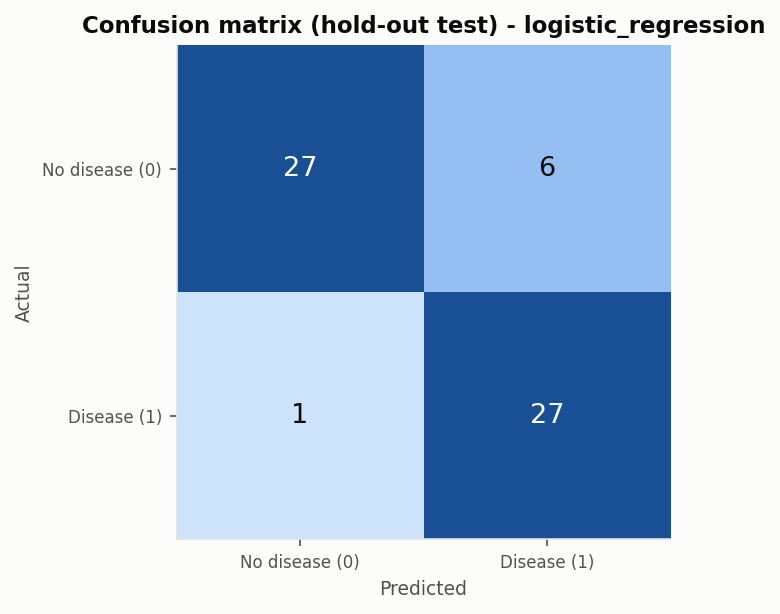

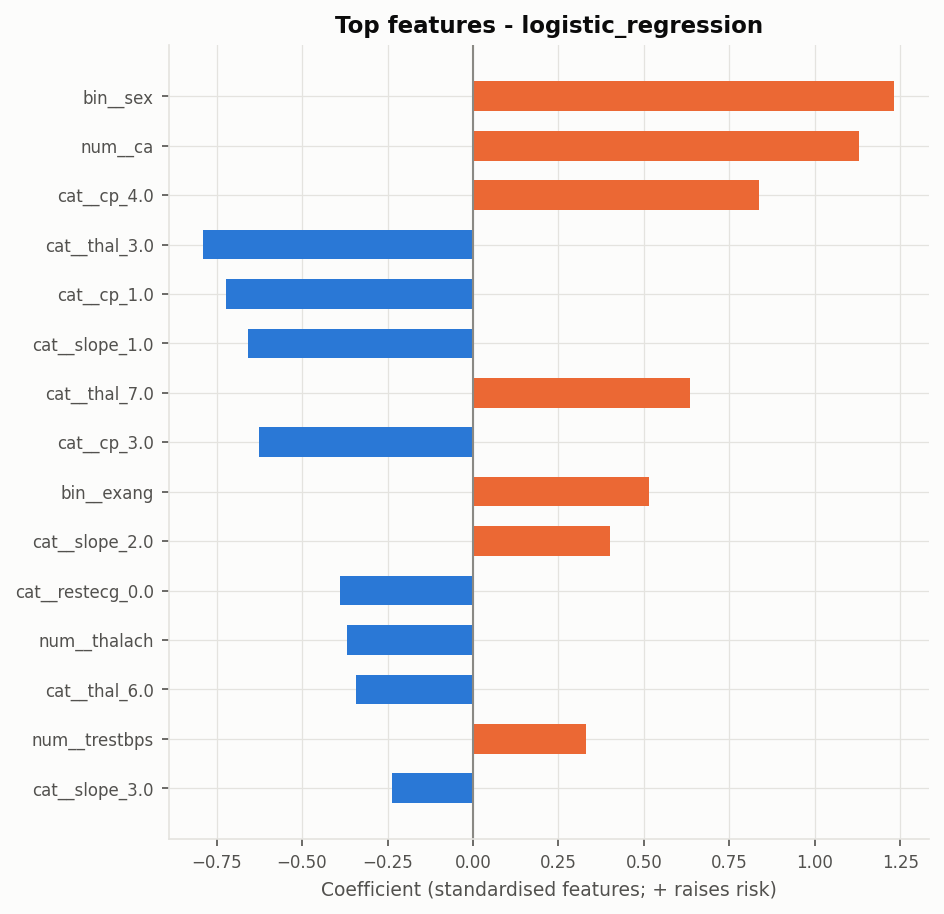

In [5]:
from IPython.display import Image, display
display(Image('reports/figures/models/model_comparison.png'))
sel = m['selected_model']
for f in ['roc_curve','confusion_matrix','feature_importance']:
    display(Image(f'reports/figures/models/{sel}/{f}.png'))

## Runs recorded in MLflow

In [6]:
import mlflow
mlflow.set_tracking_uri('sqlite:///mlflow.db')
runs = mlflow.search_runs(experiment_names=['heart-disease-uci'])
print(runs['tags.run_level'].value_counts())
runs[runs['tags.run_level']=='parent'][['tags.mlflow.runName','metrics.cv_roc_auc_mean','metrics.test_roc_auc','start_time']]

INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


tags.run_level
child        72
parent        3
selection     1
Name: count, dtype: int64


,tags.mlflow.runName,metrics.cv_roc_auc_mean,metrics.test_roc_auc,start_time
17,gradient_boosting,0.875515,0.953463,2026-10-16 14:51:39.867000+00:00
42,random_forest,0.900536,0.959957,2026-10-16 14:50:38.254000+00:00
75,logistic_regression,0.907148,0.958874,2026-10-16 14:49:23.838000+00:00
